# Step 8 — Hierarchical clustering (exploratory regime selection)

## Domains

The notebook is organised in two parts: **Europe** (`REGION = "europe"`, first half), then **North America** (`REGION = "northamerica"`, second half). Helper functions in the fifth code cell are shared.

## Purpose
Perform **Ward hierarchical clustering** on PCA-reduced Z500 states to explore whether discrete circulation regimes exist and to identify a defensible candidate range for the number of regimes (typically \(k \approx 4\)–\(8\)).

## Input
- `PCs_reduced(time, mode)` from Step 7 (`pipeline_prepro.py` / `preprocessing_helpers.py`; originally prototyped in the now-retired `07_PCA.ipynb`)

## Output
- Ward linkage matrix `Z`
- dendrogram + distance-jump diagnostics
- candidate cluster labels for selected \(k\)

## Role in workflow
Exploratory step between PCA (Step 7) and final clustering / regime definition (Step 9).


In [1]:
from __future__ import annotations

from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from common.map_plotting_helpers import add_contextily_basemap_under_spatial_raster as _add_map_basemap
from common.preprocessing_helpers import bbox_step_filename_suffix, find_module_root

from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.dpi": 120})

# module_root resolved via find_module_root() so this notebook works
# regardless of its own location under src/ (interactive or headless nbconvert).
module_root = find_module_root()

# ------------------------
# Configuration
# ------------------------

REGION = "europe"  # "europe" | "northamerica"
BBOX_STEP: str | None = "B5"  # e.g. "B0".."B5" if you ran the pipeline with bbox shrinking steps
BBOX_STEP = (str(BBOX_STEP).strip().upper() if BBOX_STEP else None)


BBOX_OUT_TAG = bbox_step_filename_suffix(module_root, REGION, BBOX_STEP)

preprocessed_dir = module_root / "data" / "preprocessed" / REGION
processed_dir = module_root / "data" / "processed" / REGION

YEAR_START = 1979
YEAR_END = 2025
YEAR_SPAN = f"{YEAR_START}-{YEAR_END}" if YEAR_START != YEAR_END else f"{YEAR_START}"

# Must match Step 7 PCA output
WINDOW_DAYS = 11
EPSILON_M = 20.0
VAR_THRESHOLD = 0.90


def _pick_single(paths: list[Path], *, kind: str) -> Path:
    if len(paths) == 1:
        return paths[0]
    if len(paths) == 0:
        raise FileNotFoundError(f"No candidates found for {kind}.")
    names = "\n  - " + "\n  - ".join(p.name for p in paths)
    raise FileNotFoundError(f"Ambiguous candidates for {kind} ({len(paths)}). Please refine config. Candidates:{names}")


def resolve_step7_pca(
    processed_dir: Path, window_days: int, epsilon_m: float, var_threshold: float, *, year_span: str, bbox_step: str | None
) -> Path:
    eps = int(round(epsilon_m))
    var = int(var_threshold * 100)
    pats = [
        f"07_Z500_PCA_w{window_days:02d}_eps{eps:02d}_var{var:02d}_*_{year_span}.nc",
        f"07_Z500_PCA_w{window_days:02d}_eps{eps:02d}_var{var:02d}_{year_span}.nc",
        f"07_Z500_PCA_w{window_days:02d}_eps{eps:02d}_var{var:02d}.nc",
    ]
    cands: list[Path] = []
    for pat in pats:
        cands.extend(sorted(processed_dir.glob(pat)))
    if bbox_step:
        step = str(bbox_step).strip()
        step_hits = [p for p in cands if f"_step{step}_" in p.name]
        if step_hits:
            cands = step_hits
    seen: set[Path] = set()
    unique: list[Path] = []
    for p in cands:
        if p not in seen and p.exists():
            seen.add(p)
            unique.append(p)
    return _pick_single(unique, kind=f"Step 7 PCA (REGION={REGION}, w={window_days}, eps={eps}, var={var}, years={year_span}, bbox_step={bbox_step})")


def resolve_step4_6_preproc(
    preprocessed_dir: Path, window_days: int, epsilon_m: float, *, year_span: str, bbox_step: str | None
) -> Path:
    eps_label = int(round(float(epsilon_m)))
    pats = [
        f"04_05_06_Z500_preprocessed_w{window_days:02d}_eps{eps_label:02d}_*_{year_span}.nc",
        f"04_05_06_Z500_preprocessed_w{window_days:02d}_eps{eps_label:02d}_{year_span}.nc",
        f"04_05_06_Z500_preprocessed_w{window_days:02d}_eps{eps_label:02d}.nc",
    ]
    cands: list[Path] = []
    for pat in pats:
        cands.extend(sorted(preprocessed_dir.glob(pat)))
    if bbox_step:
        step = str(bbox_step).strip()
        step_hits = [p for p in cands if f"_step{step}_" in p.name]
        if step_hits:
            cands = step_hits
    seen: set[Path] = set()
    unique: list[Path] = []
    for p in cands:
        if p not in seen and p.exists():
            seen.add(p)
            unique.append(p)
    return _pick_single(unique, kind=f"Step 4–6 preprocessed (REGION={REGION}, w={window_days}, eps={eps_label}, years={year_span}, bbox_step={bbox_step})")


paths = {
    "in_pca": resolve_step7_pca(processed_dir, WINDOW_DAYS, EPSILON_M, VAR_THRESHOLD, year_span=YEAR_SPAN, bbox_step=BBOX_STEP),
    "in_preproc": resolve_step4_6_preproc(preprocessed_dir, WINDOW_DAYS, EPSILON_M, year_span=YEAR_SPAN, bbox_step=BBOX_STEP),
    "out_hc": processed_dir / f"08_Z500_HC_Ward_w{WINDOW_DAYS:02d}_eps{int(round(EPSILON_M)):02d}_var{int(VAR_THRESHOLD*100):02d}_{YEAR_SPAN}{BBOX_OUT_TAG}.nc",
}

paths

{'in_pca': PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/processed/europe/07_Z500_PCA_w11_eps20_var90_1979-2025.nc'),
 'in_preproc': PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/preprocessed/europe/04_05_06_Z500_preprocessed_w11_eps20_detrdm_clims_sigsc_stepB5_N59p0W3p0S45p0E20p0_1979-2025.nc'),
 'out_hc': PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/processed/europe/08_Z500_HC_Ward_w11_eps20_var90_1979-2025.nc')}

In [ ]:
# Figures aligned with the CLI PDF Step 8 pages (`summary_reports/step0809_render.py`).
from common.step08_09_figures import (
    build_figure_pc12_ward,
    build_figure_regime_frequency_bar,
    build_figure_silhouette_vs_k,
)


In [2]:
ds = xr.open_dataset(paths["in_pca"], chunks=None)

if "PCs_reduced" not in ds:
    raise KeyError(f"Expected 'PCs_reduced' in {paths['in_pca']}, found: {list(ds.data_vars)}")

PC_da = ds["PCs_reduced"].load()

# infer time dim name used in preprocessing (often valid_time)
time_dim = PC_da.dims[0]
mode_dim = PC_da.dims[1]

time_coord = PC_da[time_dim] if time_dim in PC_da.coords else ds[time_dim]

X_pca = np.asarray(PC_da.values, dtype=np.float32)
finite_frac = float(np.isfinite(X_pca).mean())
print("PCs_reduced shape:", X_pca.shape)
print("finite fraction:", finite_frac)
assert finite_frac == 1.0

# Optional: standardise PCs for clustering? (Usually NOT needed; PCs already reflect variance ordering.)
# If you want equal-weight PCs, uncomment:
# X_pca = (X_pca - X_pca.mean(axis=0, keepdims=True)) / (X_pca.std(axis=0, keepdims=True) + 1e-12)

ds

/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PCs_reduced shape: (7191, 3)
finite fraction: 1.0


<xarray.Dataset> Size: 302kB
Dimensions:                        (valid_time: 7191, mode: 3, space: 3933,
                                    latitude: 57, longitude: 69)
Coordinates:
  * valid_time                     (valid_time) datetime64[ns] 58kB 1979-05-0...
  * mode                           (mode) int64 24B 0 1 2
  * space                          (space) int64 31kB 0 1 2 3 ... 3930 3931 3932
  * latitude                       (latitude) float64 456B 59.0 58.75 ... 45.0
  * longitude                      (longitude) float64 552B 3.0 3.25 ... 20.0
    number                         int64 8B 0
Data variables:
    PCs_reduced                    (valid_time, mode) float32 86kB -119.8 ......
    EOFs_space                     (mode, space) float32 47kB ...
    EOF_maps                       (mode, latitude, longitude) float32 47kB ...
    explained_variance_ratio       (mode) float32 12B ...
    cumulative_explained_variance  (mode) float32 12B ...
    latitude_space                 (space) float32 16kB ...
    longitude_space                (space) float32 16kB ...
Attributes: (12/68)
    GRIB_paramId:                             129
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      115921
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    sigma_mode:                               scalar
    source_preprocessing:                     /Users/marie-christineckert/Nex...
    var_threshold:                            0.9
    k:                                        3
    pca_convention:                           flip each EOF/PC so max(|EOF|) ...
    flattening_order:                         lat outer, lon inner (xarray st...

In [3]:
# Load preprocessing output for composites in physical space
# We composite the *actual* weighted anomaly fields (not centroid reconstructions).

ds_pre = xr.open_dataset(paths["in_preproc"], chunks=None)
if "X_matrix" not in ds_pre:
    raise KeyError(f"Expected 'X_matrix' in {paths['in_preproc']}, found: {list(ds_pre.data_vars)}")

Xmat_da = ds_pre["X_matrix"].load()
X_matrix = np.asarray(Xmat_da.values, dtype=np.float32)
assert X_matrix.shape[0] == X_pca.shape[0]
assert float(np.isfinite(X_matrix).mean()) == 1.0

# Get lat/lon for reshaping composites
if "z500_weighted" in ds_pre:
    z_w = ds_pre["z500_weighted"]
    lat_dim = "lat" if "lat" in z_w.dims else "latitude"
    lon_dim = "lon" if "lon" in z_w.dims else "longitude"
    lat = z_w[lat_dim].values
    lon = z_w[lon_dim].values
else:
    lat = ds_pre.get("lat", ds_pre.get("latitude"))
    lon = ds_pre.get("lon", ds_pre.get("longitude"))
    if lat is None or lon is None:
        raise KeyError("Could not infer lat/lon from preprocessing dataset.")
    lat = np.asarray(lat)
    lon = np.asarray(lon)

n_lat = int(len(lat))
n_lon = int(len(lon))

print("X_pca:", X_pca.shape)
print("X_matrix:", X_matrix.shape)
print("lat/lon:", n_lat, n_lon)

ds_pre

X_pca: (7191, 3)
X_matrix: (7191, 3933)
lat/lon: 57 69


<xarray.Dataset> Size: 340MB
Dimensions:             (valid_time: 7191, latitude: 57, longitude: 69,
                         season_day: 153, space: 3933)
Coordinates:
  * valid_time          (valid_time) datetime64[ns] 58kB 1979-05-01 ... 2025-...
  * latitude            (latitude) float64 456B 59.0 58.75 58.5 ... 45.25 45.0
  * longitude           (longitude) float64 552B 3.0 3.25 3.5 ... 19.75 20.0
  * season_day          (season_day) int64 1kB 1 2 3 4 5 ... 149 150 151 152 153
  * space               (space) int64 31kB 0 1 2 3 4 ... 3929 3930 3931 3932
    number              int64 8B 0
Data variables:
    z500_norm           (valid_time, latitude, longitude) float32 113MB ...
    sigma_season_day    (season_day) float32 612B ...
    z500_weighted       (valid_time, latitude, longitude) float32 113MB ...
    w_lat               (latitude) float32 228B ...
    season_day_of_time  (valid_time) int16 14kB ...
    X_matrix            (valid_time, space) float32 113MB -2.444 ... -0.4878
    latitude_space      (space) float32 16kB ...
    longitude_space     (space) float32 16kB ...
Attributes: (12/63)
    GRIB_paramId:                             129
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      115921
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    bbox_W:                                   3.0
    bbox_S:                                   45.0
    bbox_E:                                   20.0
    bbox_note:                                Subset applied to raw Z500 at S...
    detrend_method:                           domain_mean
    sigma_mode:                               scalar

In [4]:
# Same evaluation helpers as Step 9

def persistence_by_regime(labels: np.ndarray, n_regimes: int) -> dict[int, dict[str, float]]:
    """Mean/median run length per regime. Labels are 1..n_regimes."""
    labels = np.asarray(labels).astype(int)
    out: dict[int, dict[str, float]] = {}

    for r in range(1, n_regimes + 1):
        rl = []
        i = 0
        while i < labels.size:
            if labels[i] == r:
                j = i
                while j < labels.size and labels[j] == r:
                    j += 1
                rl.append(j - i)
                i = j
            else:
                i += 1

        if len(rl) == 0:
            out[r] = {"mean": float("nan"), "median": float("nan"), "n_runs": 0}
        else:
            arr = np.asarray(rl, dtype=int)
            out[r] = {"mean": float(np.mean(arr)), "median": float(np.median(arr)), "n_runs": int(arr.size)}

    return out


def transition_matrix(labels: np.ndarray, n_regimes: int) -> np.ndarray:
    """Count transitions i->j between consecutive days. Labels are 1..n_regimes."""
    labels = np.asarray(labels).astype(int)
    T = np.zeros((n_regimes, n_regimes), dtype=int)
    for a, b in zip(labels[:-1], labels[1:]):
        if 1 <= a <= n_regimes and 1 <= b <= n_regimes:
            T[a - 1, b - 1] += 1
    return T


def plot_transition_matrix(T: np.ndarray, title: str) -> None:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(T, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("to regime")
    ax.set_ylabel("from regime")
    ax.set_xticks(np.arange(T.shape[1]))
    ax.set_yticks(np.arange(T.shape[0]))
    ax.set_xticklabels(np.arange(1, T.shape[1] + 1))
    ax.set_yticklabels(np.arange(1, T.shape[0] + 1))
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    for i in range(T.shape[0]):
        for j in range(T.shape[1]):
            ax.text(
                j,
                i,
                str(T[i, j]),
                ha="center",
                va="center",
                color="white" if T[i, j] > T.max() / 2 else "black",
            )

    plt.tight_layout()
    plt.show()

## Diagnostics: how to interpret the plots

### Dendrogram (Ward)
**What it shows:** the sequence of agglomerative merges (from many small clusters → one big cluster) and the **merge distance** at each step.

**How to interpret:**
- **Clear vertical jumps** (big distance increases) suggest **natural separation scales**.
- **Smooth, gradual merging** suggests a more **continuous** state space (weak regime discreteness).
- If it looks *very bushy/noisy* with many tiny splits, you may be retaining **too many PCs** (or the signal-to-noise is low).

### Ward distance structure (sorted distances + jumps)
**What it shows:** the same merge distances, but rearranged to make **jumps/spikes** easy to spot.

**How to interpret:**
- Look for **spikes in Δ Ward**: those indicate merges that suddenly become much more “expensive”.
- Candidate regime counts are often **just before** such spikes (then validate with Step 9 stability + physical interpretability).

### PC-space scatter (PC1 vs PC2, colored by labels)
**What it shows:** whether candidate \(k\) labels correspond to separable structure in leading EOF dimensions.

**How to interpret:**
- Some overlap is normal in atmospheric regimes; you are looking for **tendencies/branches**, not perfect separation.
- If everything is one diffuse blob for all \(k\), regime structure is likely weak for this season/domain/PC set.

### Silhouette vs k (supporting diagnostic only)
**What it shows:** average cluster separability for each \(k\).

**How to interpret:**
- **Peak in curve → best candidate \(k\)** (supporting evidence, not a proof)
- **Flat curve → weak clustering structure** (common in summer)
- **Monotonic decrease → over-clustering** (too many regimes)

**Individual points:**
- Higher silhouette → more distinct regimes; lower → more overlap.
- Small differences between \(k\) → regime structure not strongly sensitive to \(k\).

**Local maximum (if present):**
- Suggests a natural clustering scale (often ~4–6 in many regime studies).

**Low/flat scores across all k:**
- Suggests a continuum; \(k\) becomes a methodological choice rather than a physical constant.

**Sudden drop after small k:**
- Additional clusters are likely splitting noise/gradients; prefer \(k\) before the drop.

**Very high values (\(>\) ~0.3):**
- Unusually strong separation for atmospheric regimes; double-check preprocessing / PC count / sampling.

**One-line summary:**
Silhouette analysis quantifies separability in EOF space, but should be interpreted together with dendrogram/Ward-distance structure and physical interpretability.


## Ward distance interpretability plot (how to read it)

**Panel 1 — sorted Ward distances**
- Shows the overall distribution of merge distances.
- A gentle slope means merges become gradually more expensive; strong curvature near the end suggests a few large-scale separations.

**Panel 2 — distance jumps (Δ Ward)**
- This is the main “elbow” diagnostic.
- Look for **spikes**: those indicate the hierarchy is merging clusters that are much less similar than before.

**Panel 3 — cluster merging structure (clusters remaining → distance)**
- Makes it explicit what happens as \(k\) decreases (many clusters → few clusters).
- Large increases in distance as clusters remaining becomes small indicate that merging is collapsing distinct structures.

**Rule of thumb:** pick candidate \(k\) values **just before** a large spike/jump, then validate with Step 9 stability and physical interpretability.


linkage matrix shape: (7190, 4)


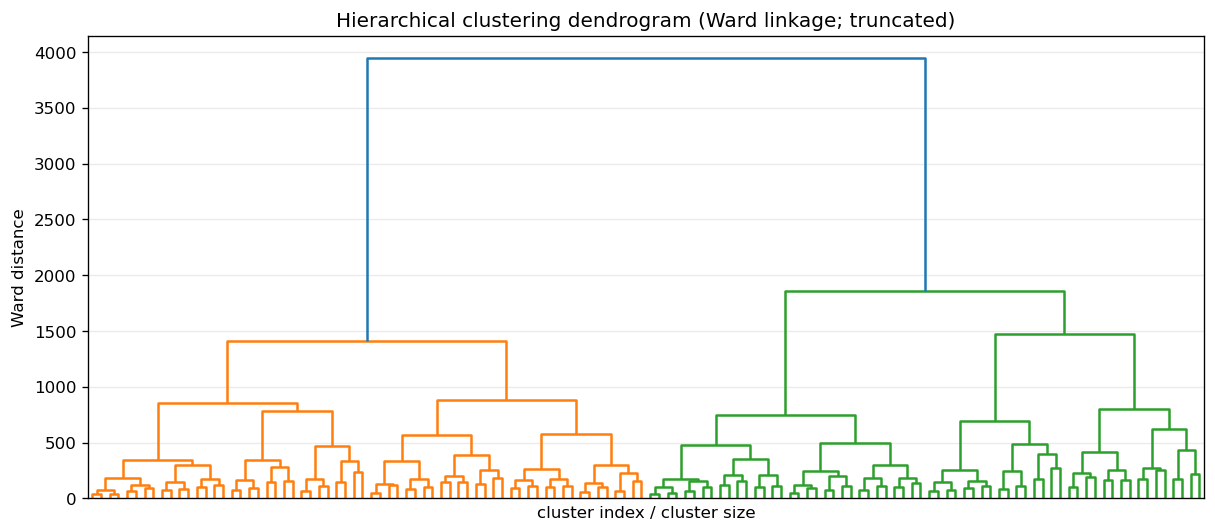

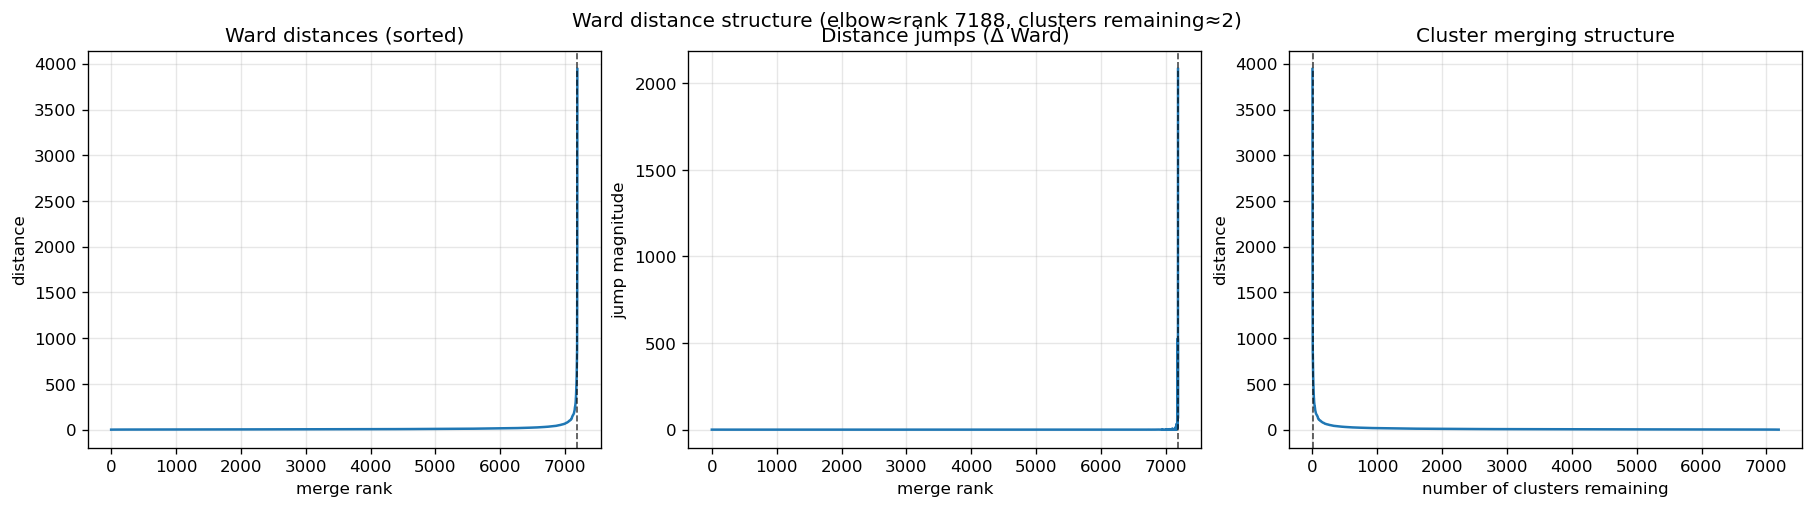

In [5]:
# Ward hierarchical clustering in PCA space
Z = linkage(X_pca, method="ward")  # (n-1, 4)
print("linkage matrix shape:", Z.shape)

# Dendrogram (truncated for readability)
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="level", p=6, no_labels=True)
plt.title("Hierarchical clustering dendrogram (Ward linkage; truncated)")
plt.xlabel("cluster index / cluster size")
plt.ylabel("Ward distance")
plt.grid(True, axis="y", alpha=0.25)
plt.show()

# Interpretable Ward-distance diagnostics
# Panel 1: sorted merge distances
# Panel 2: jumps in sorted distances (spikes suggest separation scales)
# Panel 3: distance vs implied number of clusters remaining (N -> 1)
distances = Z[:, 2]
d_sorted = np.sort(distances)
d_diff = np.diff(d_sorted)

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

axs[0].plot(d_sorted, lw=1.5)
axs[0].set_title("Ward distances (sorted)")
axs[0].set_xlabel("merge rank")
axs[0].set_ylabel("distance")
axs[0].grid(True, alpha=0.3)

axs[1].plot(d_diff, lw=1.5)
axs[1].set_title("Distance jumps (Δ Ward)")
axs[1].set_xlabel("merge rank")
axs[1].set_ylabel("jump magnitude")
axs[1].grid(True, alpha=0.3)

clusters_remaining = np.arange(len(d_sorted), 0, -1)
axs[2].plot(clusters_remaining, d_sorted, lw=1.5)
axs[2].set_title("Cluster merging structure")
axs[2].set_xlabel("number of clusters remaining")
axs[2].set_ylabel("distance")
axs[2].grid(True, alpha=0.3)

# Optional: crude elbow marker (largest jump in sorted distances)
elbow_idx = int(np.argmax(d_diff))
elbow_dist = float(d_sorted[elbow_idx])
elbow_clusters_remaining = int(clusters_remaining[elbow_idx])
axs[0].axvline(elbow_idx, color="k", ls="--", lw=1, alpha=0.7)
axs[1].axvline(elbow_idx, color="k", ls="--", lw=1, alpha=0.7)
axs[2].axvline(elbow_clusters_remaining, color="k", ls="--", lw=1, alpha=0.7)

plt.suptitle(
    f"Ward distance structure (elbow≈rank {elbow_idx}, clusters remaining≈{elbow_clusters_remaining})",
    y=1.02,
)
plt.show()

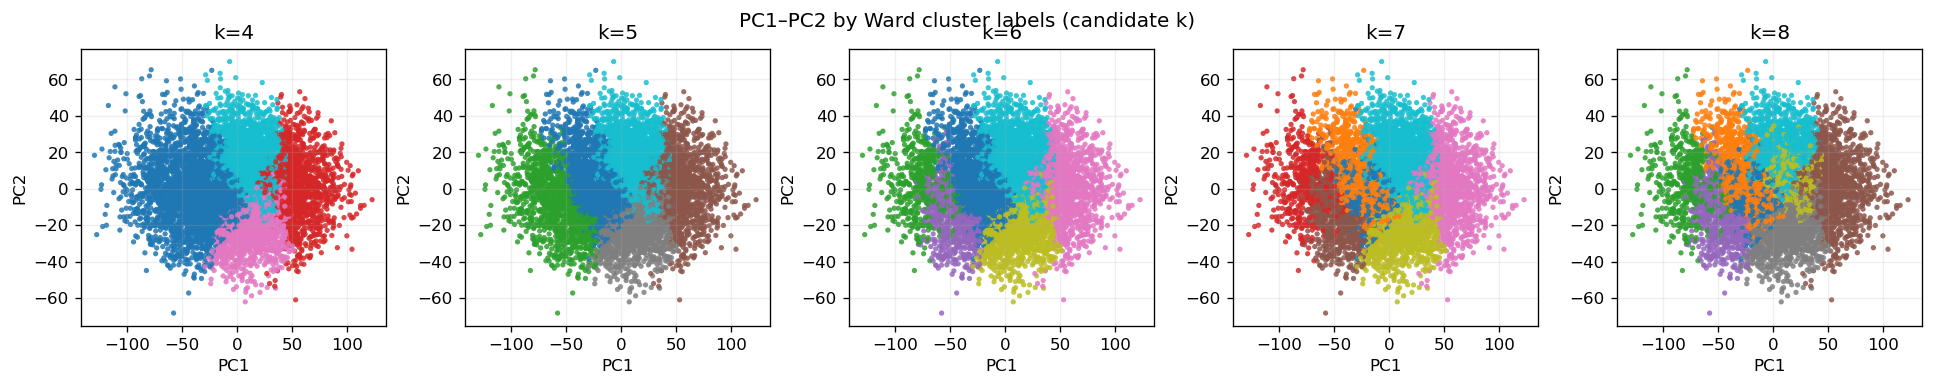

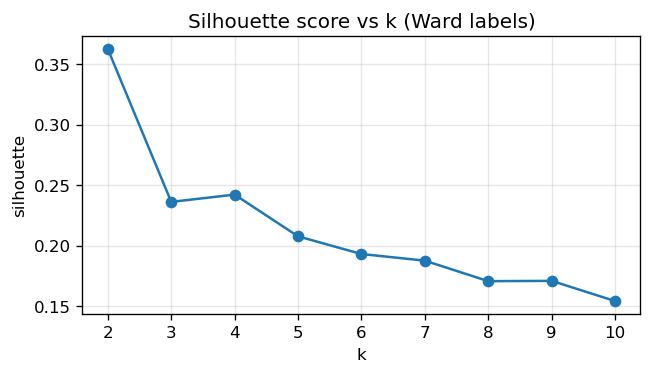

([(0, nan),
  (1, nan),
  (2, 0.36260631680488586),
  (3, 0.23618531227111816),
  (4, 0.2422250360250473)],
 [(6, 0.19306974112987518),
  (7, 0.18758000433444977),
  (8, 0.17061029374599457),
  (9, 0.17086580395698547),
  (10, 0.15415215492248535)])

In [6]:
# Candidate k selection + PC-space diagnostics

candidate_ks = list(range(4, 9))  # typical regime counts to inspect

# PC1 vs PC2 scatter, colored by labels for each k
pc1 = X_pca[:, 0]
pc2 = X_pca[:, 1] if X_pca.shape[1] > 1 else np.zeros_like(pc1)

fig, axes = plt.subplots(1, len(candidate_ks), figsize=(3.2 * len(candidate_ks), 3), constrained_layout=True)
if len(candidate_ks) == 1:
    axes = [axes]

labels_by_k: dict[int, np.ndarray] = {}

for ax, k in zip(axes, candidate_ks):
    labels = fcluster(Z, k, criterion="maxclust").astype(int)
    labels_by_k[k] = labels

    sc = ax.scatter(pc1, pc2, c=labels, s=10, cmap="tab10", alpha=0.85, linewidths=0)
    ax.set_title(f"k={k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.2)

plt.suptitle("PC1–PC2 by Ward cluster labels (candidate k)", y=1.02)
plt.show()

# Optional quantitative guide: silhouette scores (higher is better; interpret cautiously)
# Note: silhouette needs k>=2 and can be pessimistic for overlapping atmospheric regimes.
ks_scan = list(range(0, min(11, X_pca.shape[0] - 1)))
sil = []
for k in ks_scan:
    labels = fcluster(Z, k, criterion="maxclust").astype(int)

    # silhouette is undefined for k < 2
    if k < 2:
        sil.append(np.nan)
        continue

    # If a cluster ends up with 1 member, silhouette_score can error; skip those k.
    if np.min(np.bincount(labels)[1:]) < 2:
        sil.append(np.nan)
        continue

    sil.append(float(silhouette_score(X_pca, labels, metric="euclidean")))

plt.figure(figsize=(6, 3))
plt.plot(ks_scan, sil, marker="o")
plt.title("Silhouette score vs k (Ward labels)")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.grid(True, alpha=0.3)
plt.show()

list(zip(ks_scan, sil))[:5], list(zip(ks_scan, sil))[-5:]

regime_labels unique: [1 2 3 4 5 6 7]
counts: [ 539 1063  577  706 1430 1182 1694]
fractions: [0.075 0.148 0.08  0.098 0.199 0.164 0.236]


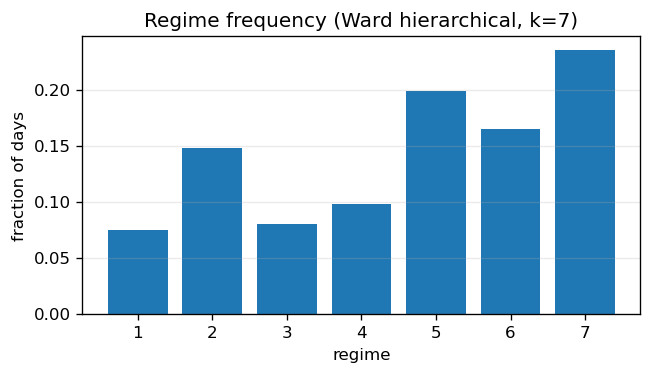

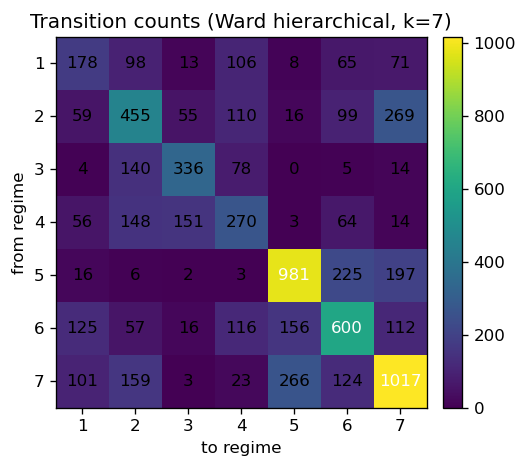

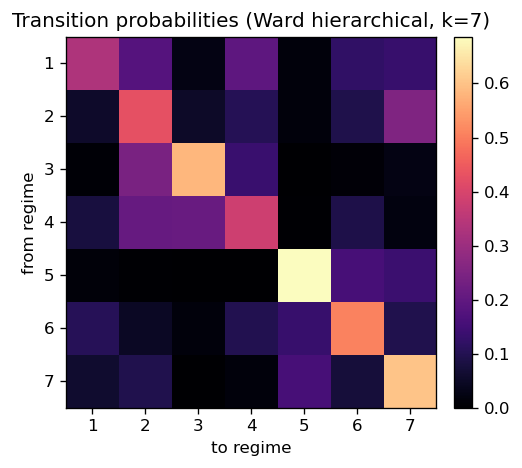

/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invali

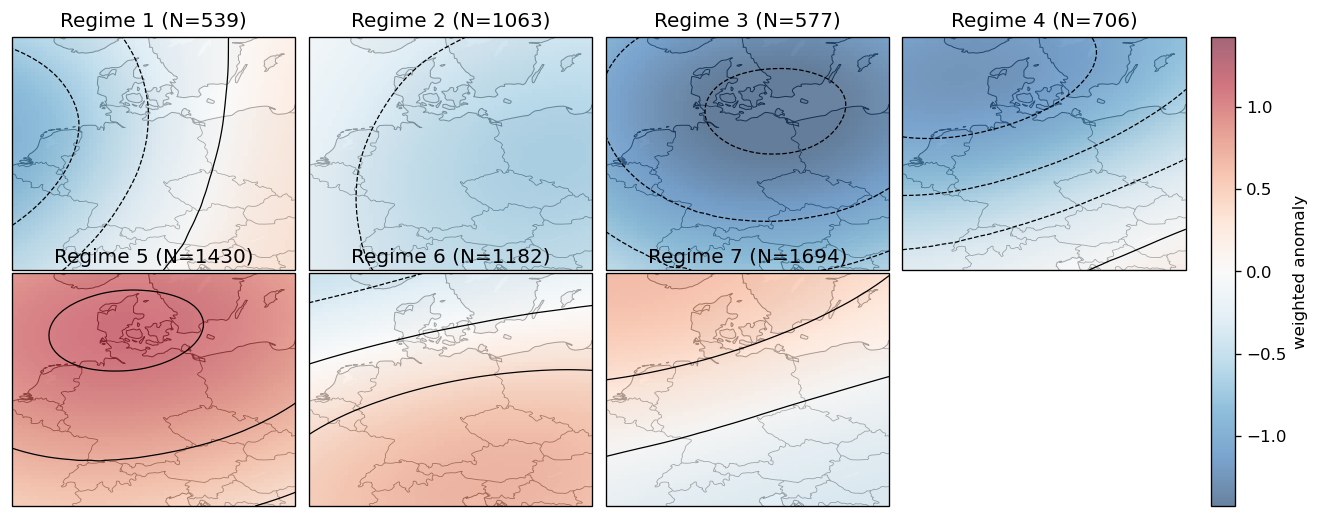

Color scale (assigned-days mean): ± 1.424099087715149


In [7]:
# Hierarchical (Ward) regime evaluation + physical-space composites (no K-means)

# Make this cell robust if helper cells weren't executed yet.
if "persistence_by_regime" not in globals():

    def persistence_by_regime(labels: np.ndarray, n_regimes: int) -> dict[int, dict[str, float]]:
        """Mean/median run length per regime. Labels are 1..n_regimes."""
        labels = np.asarray(labels).astype(int)
        out: dict[int, dict[str, float]] = {}

        for r in range(1, n_regimes + 1):
            rl = []
            i = 0
            while i < labels.size:
                if labels[i] == r:
                    j = i
                    while j < labels.size and labels[j] == r:
                        j += 1
                    rl.append(j - i)
                    i = j
                else:
                    i += 1

            if len(rl) == 0:
                out[r] = {"mean": float("nan"), "median": float("nan"), "n_runs": 0}
            else:
                arr = np.asarray(rl, dtype=int)
                out[r] = {"mean": float(np.mean(arr)), "median": float(np.median(arr)), "n_runs": int(arr.size)}

        return out


if "transition_matrix" not in globals():

    def transition_matrix(labels: np.ndarray, n_regimes: int) -> np.ndarray:
        """Count transitions i->j between consecutive days. Labels are 1..n_regimes."""
        labels = np.asarray(labels).astype(int)
        T = np.zeros((n_regimes, n_regimes), dtype=int)
        for a, b in zip(labels[:-1], labels[1:]):
            if 1 <= a <= n_regimes and 1 <= b <= n_regimes:
                T[a - 1, b - 1] += 1
        return T


if "plot_transition_matrix" not in globals():

    def plot_transition_matrix(T: np.ndarray, title: str) -> None:
        fig, ax = plt.subplots(figsize=(4.5, 4))
        im = ax.imshow(T, cmap="viridis")
        ax.set_title(title)
        ax.set_xlabel("to regime")
        ax.set_ylabel("from regime")
        ax.set_xticks(np.arange(T.shape[1]))
        ax.set_yticks(np.arange(T.shape[0]))
        ax.set_xticklabels(np.arange(1, T.shape[1] + 1))
        ax.set_yticklabels(np.arange(1, T.shape[0] + 1))
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        for i in range(T.shape[0]):
            for j in range(T.shape[1]):
                ax.text(
                    j,
                    i,
                    str(T[i, j]),
                    ha="center",
                    va="center",
                    color="white" if T[i, j] > T.max() / 2 else "black",
                )

        plt.tight_layout()
        plt.show()


HC_K = 7  # set to the k you want to inspect

regime_labels = fcluster(Z, HC_K, criterion="maxclust").astype(int)  # 1..HC_K

# Regime frequency, persistence, transitions (same diagnostics as Step 9)
counts = np.bincount(regime_labels, minlength=HC_K + 1)[1:]
frac = counts / counts.sum()

print("regime_labels unique:", np.unique(regime_labels))
print("counts:", counts)
print("fractions:", np.round(frac, 3))

plt.figure(figsize=(6, 3))
plt.bar(np.arange(1, HC_K + 1), frac)
plt.title(f"Regime frequency (Ward hierarchical, k={HC_K})")
plt.xlabel("regime")
plt.ylabel("fraction of days")
plt.grid(True, axis="y", alpha=0.25)
plt.show()

pers = persistence_by_regime(regime_labels, HC_K)
pers

T = transition_matrix(regime_labels, HC_K)
plot_transition_matrix(T, title=f"Transition counts (Ward hierarchical, k={HC_K})")

# Normalised transition probabilities (row-normalised)
row_sum = T.sum(axis=1, keepdims=True)
P = np.where(row_sum > 0, T / row_sum, np.nan)

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(P, cmap="magma", vmin=0, vmax=np.nanmax(P))
ax.set_title(f"Transition probabilities (Ward hierarchical, k={HC_K})")
ax.set_xlabel("to regime")
ax.set_ylabel("from regime")
ax.set_xticks(np.arange(HC_K))
ax.set_yticks(np.arange(HC_K))
ax.set_xticklabels(np.arange(1, HC_K + 1))
ax.set_yticklabels(np.arange(1, HC_K + 1))
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# Regime composites in physical space (using the *actual* weighted fields)
# X_matrix is (time, space) with deterministic (lat outer, lon inner) order.

X_maps = X_matrix.reshape((X_matrix.shape[0], n_lat, n_lon))

composites = np.zeros((HC_K, n_lat, n_lon), dtype=np.float32)

for r in range(1, HC_K + 1):
    idx = np.where(regime_labels == r)[0]
    if idx.size == 0:
        composites[r - 1, :, :] = np.nan
        continue
    composites[r - 1, :, :] = np.mean(X_maps[idx, :, :], axis=0)

# Plot composites (Cartopy-style, like Step 10/11)
import inspect

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
except Exception as e:
    raise ImportError(
        "Cartopy is required for this composite plotting layout. "
        "If you don't have it installed in this environment, either install cartopy or revert to the simple pcolormesh plot."
    ) from e

if "data_crs" not in globals():
    data_crs = ccrs.PlateCarree()

# Extent for maps
extent = [float(np.min(lon)), float(np.max(lon)), float(np.min(lat)), float(np.max(lat))]

# If the kernel still has the old Contextily helper bound to `_add_map_basemap`,
# override it with the Cartopy version that supports `extent`.
_needs_override = (
    "_add_map_basemap" not in globals() or "extent" not in inspect.signature(_add_map_basemap).parameters
)
if _needs_override:

    def _add_map_basemap(
        ax,
        *,
        extent=None,
        zorder: float = 0,
        linewidth: float = 0.6,
        land_color: str = "#f2f2f2",
        ocean_color: str = "#ffffff",
    ) -> None:
        ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=ocean_color, edgecolor="none", zorder=zorder)
        ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor=land_color, edgecolor="none", zorder=zorder + 0.1)
        ax.add_feature(cfeature.LAKES.with_scale("50m"), facecolor=ocean_color, edgecolor="none", zorder=zorder + 0.2)

        ax.coastlines(resolution="50m", linewidth=linewidth, color="0.2", zorder=zorder + 1.0)
        ax.add_feature(
            cfeature.BORDERS.with_scale("50m"),
            linewidth=linewidth * 0.8,
            edgecolor="0.2",
            facecolor="none",
            zorder=zorder + 1.1,
        )

        if extent is not None:
            ax.set_extent(extent, crs=ccrs.PlateCarree())

ncol = min(4, HC_K)
nrow = int(np.ceil(HC_K / ncol))

vmax = float(np.nanpercentile(np.abs(composites), 98))
contour_levels = np.linspace(-vmax, vmax, 9)

fig, axes = plt.subplots(
    nrow,
    ncol,
    figsize=(3.4 * ncol, 2.3 * nrow),
    constrained_layout=False,
    subplot_kw={"projection": data_crs},
)
axes = np.atleast_1d(axes).ravel()

fig.subplots_adjust(wspace=0.02, hspace=0.01, top=0.93, bottom=0.08)

im = None
for i, r in enumerate(range(1, HC_K + 1)):
    ax = axes[i]
    n_days = int((regime_labels == r).sum())

    im = ax.pcolormesh(
        lon,
        lat,
        composites[r - 1],
        shading="auto",
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        alpha=0.6,
        transform=data_crs,
        zorder=2,
    )
    _add_map_basemap(ax, extent=extent, zorder=0)
    ax.contour(
        lon,
        lat,
        composites[r - 1],
        levels=contour_levels,
        colors="k",
        linewidths=0.75,
        transform=data_crs,
        zorder=5,
    )
    ax.set_title(f"Regime {r} (N={n_days})")

    row, col = divmod(i, ncol)
    is_bottom = row == nrow - 1
    is_left = col == 0
    ax.tick_params(axis="x", which="both", bottom=is_bottom, top=False, labelbottom=is_bottom)
    ax.tick_params(axis="y", which="both", left=is_left, right=False, labelleft=is_left)
    if is_bottom:
        ax.set_xlabel("lon")
    if is_left:
        ax.set_ylabel("lat")

for j in range(HC_K, axes.size):
    axes[j].axis("off")

fig.colorbar(im, ax=axes[:HC_K].tolist(), fraction=0.046, pad=0.02, label="weighted anomaly")
plt.show()

print("Color scale (assigned-days mean): ±", vmax)

In [8]:
# Save linkage + labels for candidate k to NetCDF for reproducibility

Z_da = xr.DataArray(
    Z.astype(np.float32),
    dims=["merge", "col"],
    coords={"merge": np.arange(Z.shape[0], dtype=int), "col": ["idx1", "idx2", "dist", "n"]},
    name="ward_linkage",
)

out = xr.Dataset(
    data_vars={
        "ward_linkage": Z_da,
    },
    attrs=dict(ds.attrs),
)

# Save candidate labels
for k, labels in labels_by_k.items():
    out[f"labels_k{k}"] = xr.DataArray(
        labels.astype(np.int16),
        dims=[time_dim],
        coords={time_dim: time_coord},
    )

out.attrs.update(
    {
        "step": "08_hierarchical_clustering",
        "method": "Ward linkage (agglomerative hierarchical clustering)",
        "source_pca": str(paths["in_pca"]),
        "window_days": int(WINDOW_DAYS),
        "epsilon_m": float(EPSILON_M),
        "var_threshold": float(VAR_THRESHOLD),
        "note": "Use as exploratory guidance for selecting candidate regime counts; final regimes defined in Step 9.",
    }
)

paths["out_hc"].parent.mkdir(parents=True, exist_ok=True)
out.to_netcdf(paths["out_hc"])

paths["out_hc"]

PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/processed/europe/08_Z500_HC_Ward_w11_eps20_var90_1979-2025.nc')

# North America

Same exploratory Ward hierarchy as above for **`REGION = "northamerica"`**. Run after the Europe section; shared helper definitions remain in the fifth code cell.


In [9]:
from __future__ import annotations

from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from common.map_plotting_helpers import add_contextily_basemap_under_spatial_raster as _add_map_basemap
from common.preprocessing_helpers import find_module_root

from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.dpi": 120})

# module_root resolved via find_module_root() so this notebook works
# regardless of its own location under src/ (interactive or headless nbconvert).
module_root = find_module_root()

# ------------------------
# Configuration
# ------------------------

REGION = "northamerica"  # or "europe"
preprocessed_dir = module_root / "data" / "preprocessed" / REGION
processed_dir = module_root / "data" / "processed" / REGION

YEAR_START = 1979
YEAR_END = 2025
YEAR_SPAN = f"{YEAR_START}-{YEAR_END}" if YEAR_START != YEAR_END else f"{YEAR_START}"

# Must match Step 7 PCA output
WINDOW_DAYS = 21
EPSILON_M = 20.0
VAR_THRESHOLD = 0.90


def resolve_step7_pca(processed_dir: Path, window_days: int, epsilon_m: float, var_threshold: float, *, year_span: str) -> Path:
    expected = processed_dir / f"07_Z500_PCA_w{window_days:02d}_eps{int(round(epsilon_m)):02d}_var{int(var_threshold*100):02d}_{year_span}.nc"
    if expected.exists():
        return expected

    legacy = processed_dir / f"07_Z500_PCA_w{window_days:02d}_eps{int(round(epsilon_m)):02d}_var{int(var_threshold*100):02d}.nc"
    if legacy.exists():
        return legacy

    available = sorted(x.name for x in processed_dir.glob("07_Z500_PCA_w*_eps*_var*.nc"))
    raise FileNotFoundError(
        f"Could not find Step 7 PCA file for year_span={year_span!r} in {processed_dir}. "
        f"Expected {expected.name}. Available: {available}"
    )


def resolve_step4_6_preproc(preprocessed_dir: Path, window_days: int, epsilon_m: float, *, year_span: str) -> Path:
    eps_label = int(round(float(epsilon_m)))
    expected = preprocessed_dir / f"04_05_06_Z500_preprocessed_w{window_days:02d}_eps{eps_label:02d}_{year_span}.nc"
    if expected.exists():
        return expected

    legacy = preprocessed_dir / f"04_05_06_Z500_preprocessed_w{window_days:02d}_eps{eps_label:02d}.nc"
    if legacy.exists():
        return legacy

    available = sorted(x.name for x in preprocessed_dir.glob("04_05_06_Z500_preprocessed_w*_eps*.nc"))
    raise FileNotFoundError(
        f"Could not find Step 4–6 preprocessed file for year_span={year_span!r} in {preprocessed_dir}. "
        f"Expected {expected.name}. Available: {available}"
    )


# Drop objects from the Europe block so hierarchical-clustering state is not mixed across domains
for _name in (
    "ds",
    "ds_pre",
    "PC_da",
    "Xmat_da",
    "time_dim",
    "mode_dim",
    "time_coord",
    "X_pca",
    "X_matrix",
    "lat",
    "lon",
    "lat_dim",
    "lon_dim",
    "n_lat",
    "n_lon",
    "Z",
    "distances",
    "d_sorted",
    "d_diff",
    "clusters_remaining",
    "elbow_idx",
    "elbow_dist",
    "elbow_clusters_remaining",
    "labels_by_k",
    "regime_labels",
    "counts",
    "frac",
    "pers",
    "T",
    "P",
    "X_maps",
    "composites",
    "out",
    "Z_da",
    "sil",
    "ks_scan",
    "candidate_ks",
    "pc1",
    "pc2",
    "HC_K",
):
    globals().pop(_name, None)

paths = {
    "in_pca": resolve_step7_pca(processed_dir, WINDOW_DAYS, EPSILON_M, VAR_THRESHOLD, year_span=YEAR_SPAN),
    "in_preproc": resolve_step4_6_preproc(preprocessed_dir, WINDOW_DAYS, EPSILON_M, year_span=YEAR_SPAN),
    "out_hc": processed_dir
    / f"08_Z500_HC_Ward_w{WINDOW_DAYS:02d}_eps{int(round(EPSILON_M)):02d}_var{int(VAR_THRESHOLD*100):02d}_{YEAR_SPAN}.nc",
}

paths

{'in_pca': PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/processed/northamerica/07_Z500_PCA_w21_eps20_var90_1979-2025.nc'),
 'in_preproc': PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/preprocessed/northamerica/04_05_06_Z500_preprocessed_w21_eps20_1979-2025.nc'),
 'out_hc': PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/processed/northamerica/08_Z500_HC_Ward_w21_eps20_var90_1979-2025.nc')}

In [10]:
ds = xr.open_dataset(paths["in_pca"], chunks=None)

if "PCs_reduced" not in ds:
    raise KeyError(f"Expected 'PCs_reduced' in {paths['in_pca']}, found: {list(ds.data_vars)}")

PC_da = ds["PCs_reduced"].load()

# infer time dim name used in preprocessing (often valid_time)
time_dim = PC_da.dims[0]
mode_dim = PC_da.dims[1]

time_coord = PC_da[time_dim] if time_dim in PC_da.coords else ds[time_dim]

X_pca = np.asarray(PC_da.values, dtype=np.float32)
finite_frac = float(np.isfinite(X_pca).mean())
print("PCs_reduced shape:", X_pca.shape)
print("finite fraction:", finite_frac)
assert finite_frac == 1.0

# Optional: standardise PCs for clustering? (Usually NOT needed; PCs already reflect variance ordering.)
# If you want equal-weight PCs, uncomment:
# X_pca = (X_pca - X_pca.mean(axis=0, keepdims=True)) / (X_pca.std(axis=0, keepdims=True) + 1e-12)

ds

PCs_reduced shape: (7191, 39)
finite fraction: 1.0


<xarray.Dataset> Size: 49MB
Dimensions:                        (valid_time: 7191, mode: 39, space: 144841,
                                    latitude: 241, longitude: 601)
Coordinates:
  * valid_time                     (valid_time) datetime64[ns] 58kB 1979-05-0...
  * mode                           (mode) int64 312B 0 1 2 3 4 ... 35 36 37 38
  * space                          (space) int64 1MB 0 1 2 ... 144839 144840
  * latitude                       (latitude) float64 2kB 80.0 79.75 ... 20.0
  * longitude                      (longitude) float64 5kB -180.0 ... -30.0
Data variables:
    PCs_reduced                    (valid_time, mode) float32 1MB -38.89 ... ...
    EOFs_space                     (mode, space) float32 23MB ...
    EOF_maps                       (mode, latitude, longitude) float32 23MB ...
    explained_variance_ratio       (mode) float32 156B ...
    cumulative_explained_variance  (mode) float32 156B ...
    latitude_space                 (space) float32 579kB ...
    longitude_space                (space) float32 579kB ...
Attributes: (12/13)
    step:                     07_PCA
    source_preprocessed:      /work/bb1546/detect_weather/data/preprocessed/n...
    var_threshold:            0.9
    k:                        39
    pca_convention:           flip each EOF/PC so max(|EOF|) is positive
    flattening_order:         lat outer, lon inner (xarray stack space=(lat,l...
    ...                       ...
    year_start:               1979
    year_end:                 2025
    preprocessing_step:       07_Z500_PCA
    season:                   MJJAS
    region:                   northamerica
    climatology_window_days:  21

In [11]:
# Load preprocessing output for composites in physical space
# We composite the *actual* weighted anomaly fields (not centroid reconstructions).

ds_pre = xr.open_dataset(paths["in_preproc"], chunks=None)
if "X_matrix" not in ds_pre:
    raise KeyError(f"Expected 'X_matrix' in {paths['in_preproc']}, found: {list(ds_pre.data_vars)}")

Xmat_da = ds_pre["X_matrix"].load()
X_matrix = np.asarray(Xmat_da.values, dtype=np.float32)
assert X_matrix.shape[0] == X_pca.shape[0]
assert float(np.isfinite(X_matrix).mean()) == 1.0

# Get lat/lon for reshaping composites
if "z500_weighted" in ds_pre:
    z_w = ds_pre["z500_weighted"]
    lat_dim = "lat" if "lat" in z_w.dims else "latitude"
    lon_dim = "lon" if "lon" in z_w.dims else "longitude"
    lat = z_w[lat_dim].values
    lon = z_w[lon_dim].values
else:
    lat = ds_pre.get("lat", ds_pre.get("latitude"))
    lon = ds_pre.get("lon", ds_pre.get("longitude"))
    if lat is None or lon is None:
        raise KeyError("Could not infer lat/lon from preprocessing dataset.")
    lat = np.asarray(lat)
    lon = np.asarray(lon)

n_lat = int(len(lat))
n_lon = int(len(lon))

print("X_pca:", X_pca.shape)
print("X_matrix:", X_matrix.shape)
print("lat/lon:", n_lat, n_lon)

ds_pre

X_pca: (7191, 39)
X_matrix: (7191, 144841)
lat/lon: 241 601


<xarray.Dataset> Size: 13GB
Dimensions:             (valid_time: 7191, latitude: 241, longitude: 601,
                         season_day: 153, space: 144841)
Coordinates:
  * valid_time          (valid_time) datetime64[ns] 58kB 1979-05-01 ... 2025-...
    number              (valid_time) int64 58kB 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0
  * latitude            (latitude) float64 2kB 80.0 79.75 79.5 ... 20.25 20.0
  * longitude           (longitude) float64 5kB -180.0 -179.8 ... -30.25 -30.0
  * season_day          (season_day) int64 1kB 1 2 3 4 5 ... 149 150 151 152 153
  * space               (space) int64 1MB 0 1 2 3 ... 144838 144839 144840
Data variables:
    z500_norm           (valid_time, latitude, longitude) float32 4GB ...
    sigma_season_day    (season_day, latitude, longitude) float32 89MB ...
    z500_weighted       (valid_time, latitude, longitude) float32 4GB ...
    w_lat               (latitude) float32 964B ...
    season_day_of_time  (valid_time) int16 14kB ...
    X_matrix            (valid_time, space) float32 4GB -0.3817 ... -0.06049
    latitude_space      (space) float32 579kB ...
    longitude_space     (space) float32 579kB ...
Attributes: (12/50)
    GRIB_paramId:                             129
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      144841
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    flatten_order:                            lat outer, lon inner (xarray st...
    year_span:                                1979-2025
    year_start:                               1979
    year_end:                                 2025
    preprocessing_step:                       04_05_06_Z500_preprocessed
    region:                                   northamerica

## Diagnostics: how to interpret the plots

### Dendrogram (Ward)
**What it shows:** the sequence of agglomerative merges (from many small clusters → one big cluster) and the **merge distance** at each step.

**How to interpret:**
- **Clear vertical jumps** (big distance increases) suggest **natural separation scales**.
- **Smooth, gradual merging** suggests a more **continuous** state space (weak regime discreteness).
- If it looks *very bushy/noisy* with many tiny splits, you may be retaining **too many PCs** (or the signal-to-noise is low).

### Ward distance structure (sorted distances + jumps)
**What it shows:** the same merge distances, but rearranged to make **jumps/spikes** easy to spot.

**How to interpret:**
- Look for **spikes in Δ Ward**: those indicate merges that suddenly become much more “expensive”.
- Candidate regime counts are often **just before** such spikes (then validate with Step 9 stability + physical interpretability).

### PC-space scatter (PC1 vs PC2, colored by labels)
**What it shows:** whether candidate \(k\) labels correspond to separable structure in leading EOF dimensions.

**How to interpret:**
- Some overlap is normal in atmospheric regimes; you are looking for **tendencies/branches**, not perfect separation.
- If everything is one diffuse blob for all \(k\), regime structure is likely weak for this season/domain/PC set.

### Silhouette vs k (supporting diagnostic only)
**What it shows:** average cluster separability for each \(k\).

**How to interpret:**
- **Peak in curve → best candidate \(k\)** (supporting evidence, not a proof)
- **Flat curve → weak clustering structure** (common in summer)
- **Monotonic decrease → over-clustering** (too many regimes)

**Individual points:**
- Higher silhouette → more distinct regimes; lower → more overlap.
- Small differences between \(k\) → regime structure not strongly sensitive to \(k\).

**Local maximum (if present):**
- Suggests a natural clustering scale (often ~4–6 in many regime studies).

**Low/flat scores across all k:**
- Suggests a continuum; \(k\) becomes a methodological choice rather than a physical constant.

**Sudden drop after small k:**
- Additional clusters are likely splitting noise/gradients; prefer \(k\) before the drop.

**Very high values (\(>\) ~0.3):**
- Unusually strong separation for atmospheric regimes; double-check preprocessing / PC count / sampling.

**One-line summary:**
Silhouette analysis quantifies separability in EOF space, but should be interpreted together with dendrogram/Ward-distance structure and physical interpretability.


## Ward distance interpretability plot (how to read it)

**Panel 1 — sorted Ward distances**
- Shows the overall distribution of merge distances.
- A gentle slope means merges become gradually more expensive; strong curvature near the end suggests a few large-scale separations.

**Panel 2 — distance jumps (Δ Ward)**
- This is the main “elbow” diagnostic.
- Look for **spikes**: those indicate the hierarchy is merging clusters that are much less similar than before.

**Panel 3 — cluster merging structure (clusters remaining → distance)**
- Makes it explicit what happens as \(k\) decreases (many clusters → few clusters).
- Large increases in distance as clusters remaining becomes small indicate that merging is collapsing distinct structures.

**Rule of thumb:** pick candidate \(k\) values **just before** a large spike/jump, then validate with Step 9 stability and physical interpretability.


linkage matrix shape: (7190, 4)


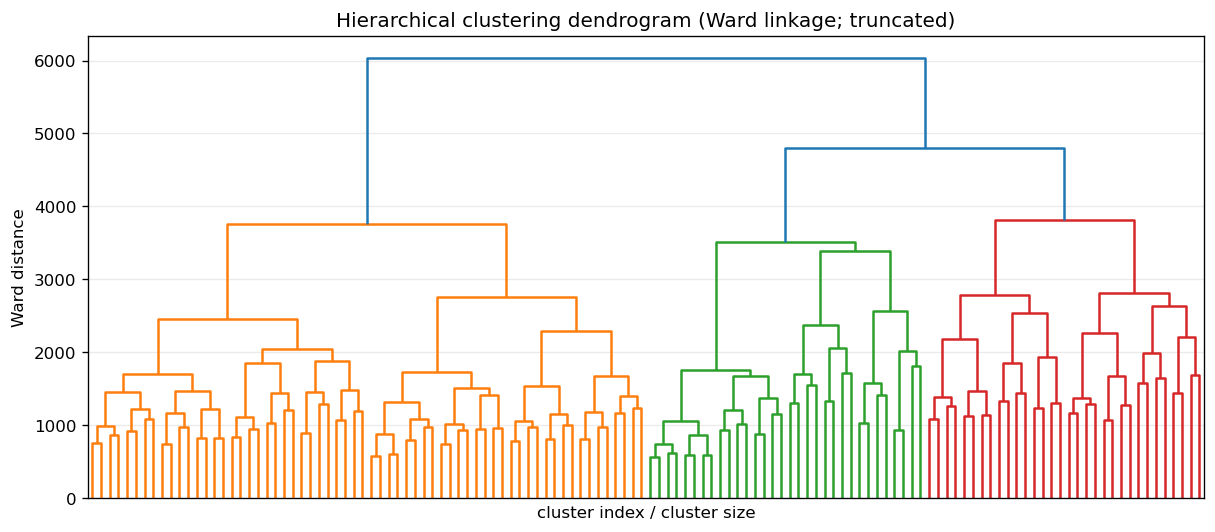

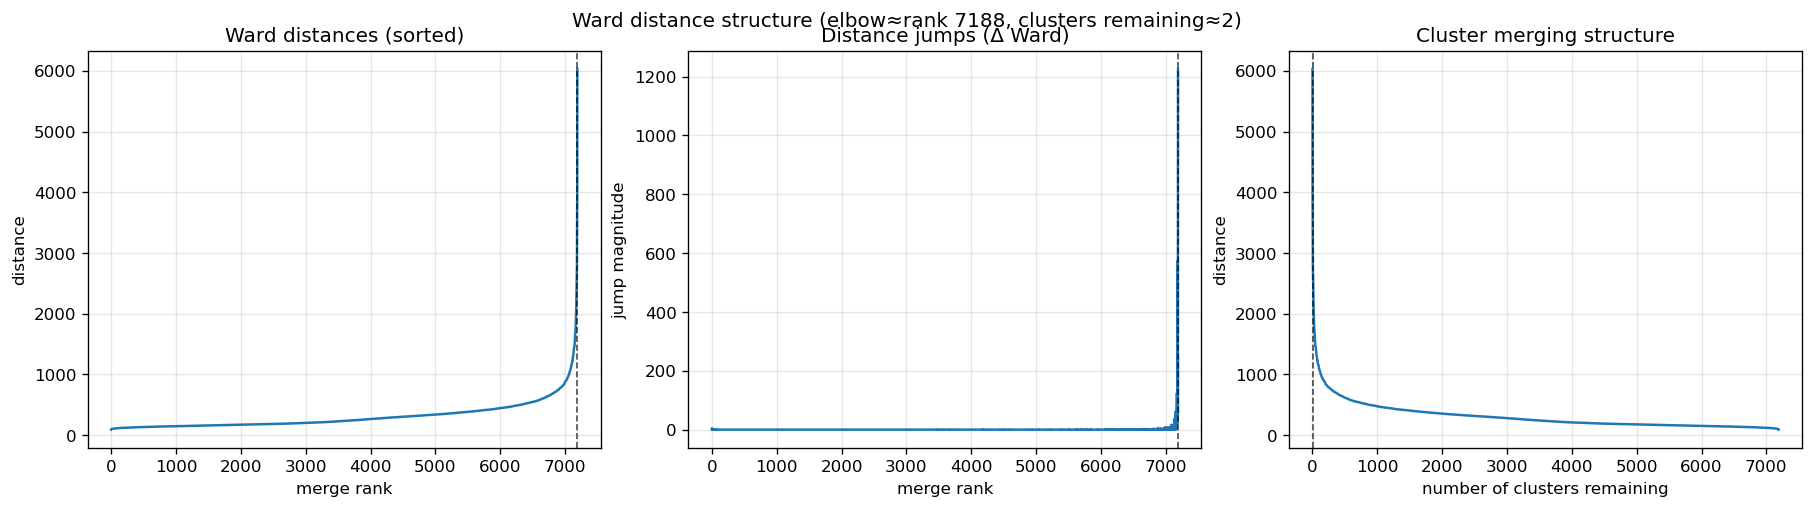

In [12]:
# Ward hierarchical clustering in PCA space
Z = linkage(X_pca, method="ward")  # (n-1, 4)
print("linkage matrix shape:", Z.shape)

# Dendrogram (truncated for readability)
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="level", p=6, no_labels=True)
plt.title("Hierarchical clustering dendrogram (Ward linkage; truncated)")
plt.xlabel("cluster index / cluster size")
plt.ylabel("Ward distance")
plt.grid(True, axis="y", alpha=0.25)
plt.show()

# Interpretable Ward-distance diagnostics
# Panel 1: sorted merge distances
# Panel 2: jumps in sorted distances (spikes suggest separation scales)
# Panel 3: distance vs implied number of clusters remaining (N -> 1)
distances = Z[:, 2]
d_sorted = np.sort(distances)
d_diff = np.diff(d_sorted)

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

axs[0].plot(d_sorted, lw=1.5)
axs[0].set_title("Ward distances (sorted)")
axs[0].set_xlabel("merge rank")
axs[0].set_ylabel("distance")
axs[0].grid(True, alpha=0.3)

axs[1].plot(d_diff, lw=1.5)
axs[1].set_title("Distance jumps (Δ Ward)")
axs[1].set_xlabel("merge rank")
axs[1].set_ylabel("jump magnitude")
axs[1].grid(True, alpha=0.3)

clusters_remaining = np.arange(len(d_sorted), 0, -1)
axs[2].plot(clusters_remaining, d_sorted, lw=1.5)
axs[2].set_title("Cluster merging structure")
axs[2].set_xlabel("number of clusters remaining")
axs[2].set_ylabel("distance")
axs[2].grid(True, alpha=0.3)

# Optional: crude elbow marker (largest jump in sorted distances)
elbow_idx = int(np.argmax(d_diff))
elbow_dist = float(d_sorted[elbow_idx])
elbow_clusters_remaining = int(clusters_remaining[elbow_idx])
axs[0].axvline(elbow_idx, color="k", ls="--", lw=1, alpha=0.7)
axs[1].axvline(elbow_idx, color="k", ls="--", lw=1, alpha=0.7)
axs[2].axvline(elbow_clusters_remaining, color="k", ls="--", lw=1, alpha=0.7)

plt.suptitle(
    f"Ward distance structure (elbow≈rank {elbow_idx}, clusters remaining≈{elbow_clusters_remaining})",
    y=1.02,
)
plt.show()

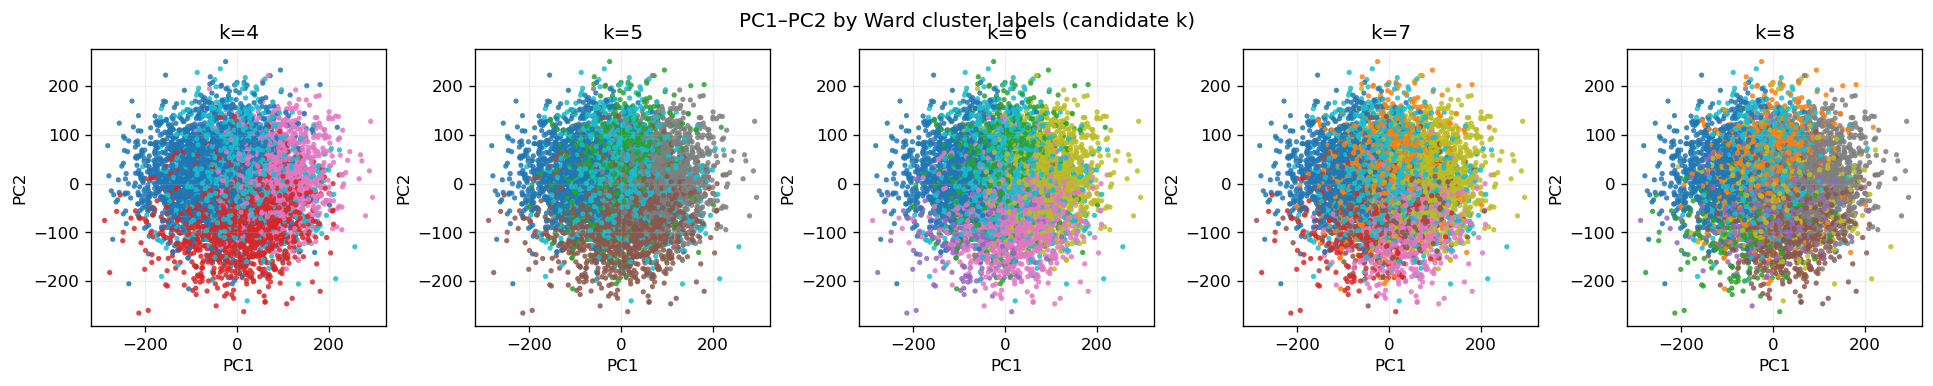

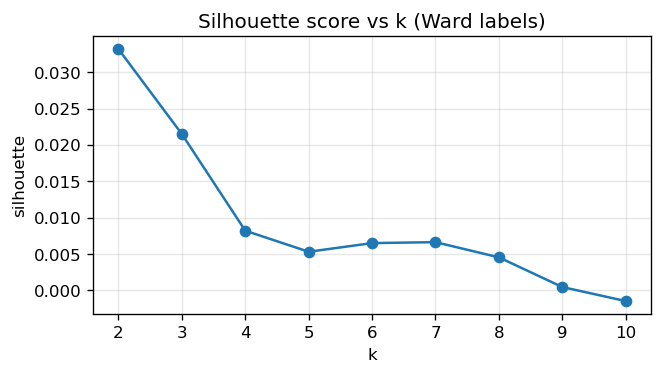

([(0, nan),
  (1, nan),
  (2, 0.03318840637803078),
  (3, 0.021496308967471123),
  (4, 0.008201105520129204)],
 [(6, 0.006494676694273949),
  (7, 0.006626758258789778),
  (8, 0.004532745573669672),
  (9, 0.0004505023534875363),
  (10, -0.0014792035799473524)])

In [13]:
# Candidate k selection + PC-space diagnostics

candidate_ks = list(range(4, 9))  # typical regime counts to inspect

# PC1 vs PC2 scatter, colored by labels for each k
pc1 = X_pca[:, 0]
pc2 = X_pca[:, 1] if X_pca.shape[1] > 1 else np.zeros_like(pc1)

fig, axes = plt.subplots(1, len(candidate_ks), figsize=(3.2 * len(candidate_ks), 3), constrained_layout=True)
if len(candidate_ks) == 1:
    axes = [axes]

labels_by_k: dict[int, np.ndarray] = {}

for ax, k in zip(axes, candidate_ks):
    labels = fcluster(Z, k, criterion="maxclust").astype(int)
    labels_by_k[k] = labels

    sc = ax.scatter(pc1, pc2, c=labels, s=10, cmap="tab10", alpha=0.85, linewidths=0)
    ax.set_title(f"k={k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True, alpha=0.2)

plt.suptitle("PC1–PC2 by Ward cluster labels (candidate k)", y=1.02)
plt.show()

# Optional quantitative guide: silhouette scores (higher is better; interpret cautiously)
# Note: silhouette needs k>=2 and can be pessimistic for overlapping atmospheric regimes.
ks_scan = list(range(0, min(11, X_pca.shape[0] - 1)))
sil = []
for k in ks_scan:
    labels = fcluster(Z, k, criterion="maxclust").astype(int)

    # silhouette is undefined for k < 2
    if k < 2:
        sil.append(np.nan)
        continue

    # If a cluster ends up with 1 member, silhouette_score can error; skip those k.
    if np.min(np.bincount(labels)[1:]) < 2:
        sil.append(np.nan)
        continue

    sil.append(float(silhouette_score(X_pca, labels, metric="euclidean")))

plt.figure(figsize=(6, 3))
plt.plot(ks_scan, sil, marker="o")
plt.title("Silhouette score vs k (Ward labels)")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.grid(True, alpha=0.3)
plt.show()

list(zip(ks_scan, sil))[:5], list(zip(ks_scan, sil))[-5:]

regime_labels unique: [1 2 3 4]
counts: [2235 2001 1339 1616]
fractions: [0.311 0.278 0.186 0.225]


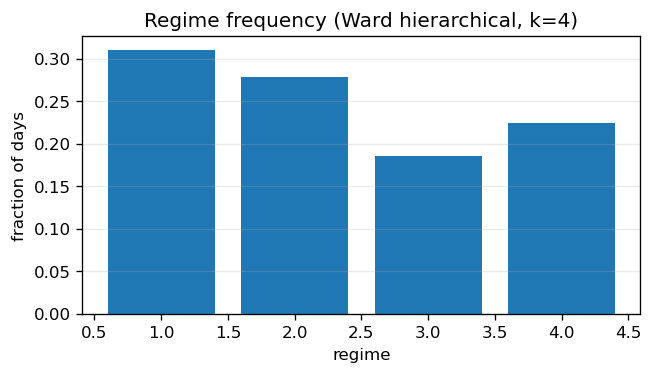

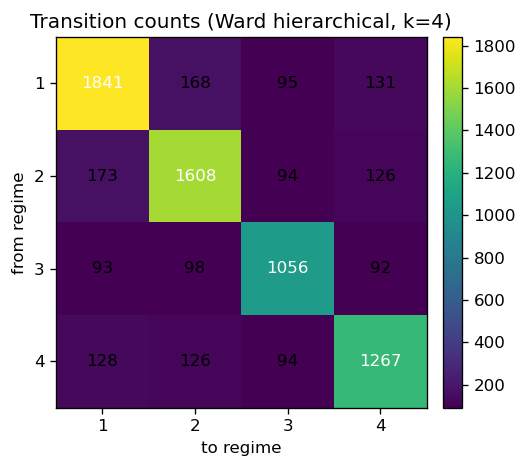

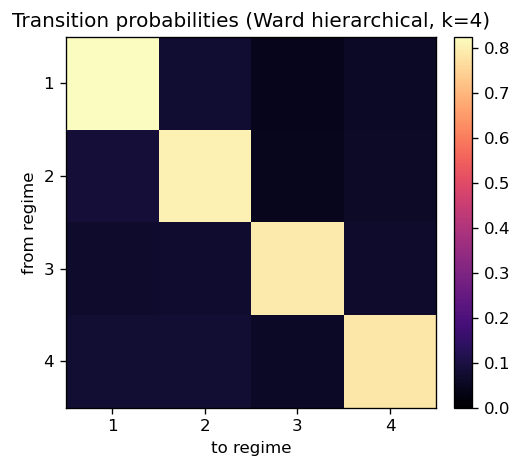

/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/meteor/lib/python3.11/site-packages/shapely/predicates.py:878: RuntimeWarning: invali

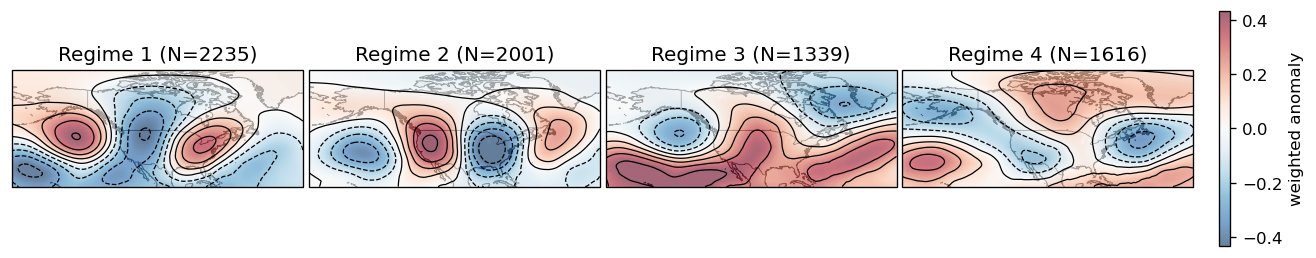

Color scale (assigned-days mean): ± 0.43204841017723083


In [14]:
# Hierarchical (Ward) regime evaluation + physical-space composites (no K-means)

# Make this cell robust if helper cells weren't executed yet.
if "persistence_by_regime" not in globals():

    def persistence_by_regime(labels: np.ndarray, n_regimes: int) -> dict[int, dict[str, float]]:
        """Mean/median run length per regime. Labels are 1..n_regimes."""
        labels = np.asarray(labels).astype(int)
        out: dict[int, dict[str, float]] = {}

        for r in range(1, n_regimes + 1):
            rl = []
            i = 0
            while i < labels.size:
                if labels[i] == r:
                    j = i
                    while j < labels.size and labels[j] == r:
                        j += 1
                    rl.append(j - i)
                    i = j
                else:
                    i += 1

            if len(rl) == 0:
                out[r] = {"mean": float("nan"), "median": float("nan"), "n_runs": 0}
            else:
                arr = np.asarray(rl, dtype=int)
                out[r] = {"mean": float(np.mean(arr)), "median": float(np.median(arr)), "n_runs": int(arr.size)}

        return out


if "transition_matrix" not in globals():

    def transition_matrix(labels: np.ndarray, n_regimes: int) -> np.ndarray:
        """Count transitions i->j between consecutive days. Labels are 1..n_regimes."""
        labels = np.asarray(labels).astype(int)
        T = np.zeros((n_regimes, n_regimes), dtype=int)
        for a, b in zip(labels[:-1], labels[1:]):
            if 1 <= a <= n_regimes and 1 <= b <= n_regimes:
                T[a - 1, b - 1] += 1
        return T


if "plot_transition_matrix" not in globals():

    def plot_transition_matrix(T: np.ndarray, title: str) -> None:
        fig, ax = plt.subplots(figsize=(4.5, 4))
        im = ax.imshow(T, cmap="viridis")
        ax.set_title(title)
        ax.set_xlabel("to regime")
        ax.set_ylabel("from regime")
        ax.set_xticks(np.arange(T.shape[1]))
        ax.set_yticks(np.arange(T.shape[0]))
        ax.set_xticklabels(np.arange(1, T.shape[1] + 1))
        ax.set_yticklabels(np.arange(1, T.shape[0] + 1))
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        for i in range(T.shape[0]):
            for j in range(T.shape[1]):
                ax.text(
                    j,
                    i,
                    str(T[i, j]),
                    ha="center",
                    va="center",
                    color="white" if T[i, j] > T.max() / 2 else "black",
                )

        plt.tight_layout()
        plt.show()


HC_K = 4  # set to the k you want to inspect

regime_labels = fcluster(Z, HC_K, criterion="maxclust").astype(int)  # 1..HC_K

# Regime frequency, persistence, transitions (same diagnostics as Step 9)
counts = np.bincount(regime_labels, minlength=HC_K + 1)[1:]
frac = counts / counts.sum()

print("regime_labels unique:", np.unique(regime_labels))
print("counts:", counts)
print("fractions:", np.round(frac, 3))

plt.figure(figsize=(6, 3))
plt.bar(np.arange(1, HC_K + 1), frac)
plt.title(f"Regime frequency (Ward hierarchical, k={HC_K})")
plt.xlabel("regime")
plt.ylabel("fraction of days")
plt.grid(True, axis="y", alpha=0.25)
plt.show()

pers = persistence_by_regime(regime_labels, HC_K)
pers

T = transition_matrix(regime_labels, HC_K)
plot_transition_matrix(T, title=f"Transition counts (Ward hierarchical, k={HC_K})")

# Normalised transition probabilities (row-normalised)
row_sum = T.sum(axis=1, keepdims=True)
P = np.where(row_sum > 0, T / row_sum, np.nan)

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(P, cmap="magma", vmin=0, vmax=np.nanmax(P))
ax.set_title(f"Transition probabilities (Ward hierarchical, k={HC_K})")
ax.set_xlabel("to regime")
ax.set_ylabel("from regime")
ax.set_xticks(np.arange(HC_K))
ax.set_yticks(np.arange(HC_K))
ax.set_xticklabels(np.arange(1, HC_K + 1))
ax.set_yticklabels(np.arange(1, HC_K + 1))
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# Regime composites in physical space (using the *actual* weighted fields)
# X_matrix is (time, space) with deterministic (lat outer, lon inner) order.

X_maps = X_matrix.reshape((X_matrix.shape[0], n_lat, n_lon))

composites = np.zeros((HC_K, n_lat, n_lon), dtype=np.float32)

for r in range(1, HC_K + 1):
    idx = np.where(regime_labels == r)[0]
    if idx.size == 0:
        composites[r - 1, :, :] = np.nan
        continue
    composites[r - 1, :, :] = np.mean(X_maps[idx, :, :], axis=0)

# Plot composites (Cartopy-style, like Step 10/11)
import inspect

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
except Exception as e:
    raise ImportError(
        "Cartopy is required for this composite plotting layout. "
        "If you don't have it installed in this environment, either install cartopy or revert to the simple pcolormesh plot."
    ) from e

if "data_crs" not in globals():
    data_crs = ccrs.PlateCarree()

# Extent for maps
extent = [float(np.min(lon)), float(np.max(lon)), float(np.min(lat)), float(np.max(lat))]

# If the kernel still has the old Contextily helper bound to `_add_map_basemap`,
# override it with the Cartopy version that supports `extent`.
_needs_override = (
    "_add_map_basemap" not in globals() or "extent" not in inspect.signature(_add_map_basemap).parameters
)
if _needs_override:

    def _add_map_basemap(
        ax,
        *,
        extent=None,
        zorder: float = 0,
        linewidth: float = 0.6,
        land_color: str = "#f2f2f2",
        ocean_color: str = "#ffffff",
    ) -> None:
        ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=ocean_color, edgecolor="none", zorder=zorder)
        ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor=land_color, edgecolor="none", zorder=zorder + 0.1)
        ax.add_feature(cfeature.LAKES.with_scale("50m"), facecolor=ocean_color, edgecolor="none", zorder=zorder + 0.2)

        ax.coastlines(resolution="50m", linewidth=linewidth, color="0.2", zorder=zorder + 1.0)
        ax.add_feature(
            cfeature.BORDERS.with_scale("50m"),
            linewidth=linewidth * 0.8,
            edgecolor="0.2",
            facecolor="none",
            zorder=zorder + 1.1,
        )

        if extent is not None:
            ax.set_extent(extent, crs=ccrs.PlateCarree())

ncol = min(4, HC_K)
nrow = int(np.ceil(HC_K / ncol))

vmax = float(np.nanpercentile(np.abs(composites), 98))
contour_levels = np.linspace(-vmax, vmax, 9)

fig, axes = plt.subplots(
    nrow,
    ncol,
    figsize=(3.4 * ncol, 2.3 * nrow),
    constrained_layout=False,
    subplot_kw={"projection": data_crs},
)
axes = np.atleast_1d(axes).ravel()

fig.subplots_adjust(wspace=0.02, hspace=0.01, top=0.93, bottom=0.08)

im = None
for i, r in enumerate(range(1, HC_K + 1)):
    ax = axes[i]
    n_days = int((regime_labels == r).sum())

    im = ax.pcolormesh(
        lon,
        lat,
        composites[r - 1],
        shading="auto",
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        alpha=0.6,
        transform=data_crs,
        zorder=2,
    )
    _add_map_basemap(ax, extent=extent, zorder=0)
    ax.contour(
        lon,
        lat,
        composites[r - 1],
        levels=contour_levels,
        colors="k",
        linewidths=0.75,
        transform=data_crs,
        zorder=5,
    )
    ax.set_title(f"Regime {r} (N={n_days})")

    row, col = divmod(i, ncol)
    is_bottom = row == nrow - 1
    is_left = col == 0
    ax.tick_params(axis="x", which="both", bottom=is_bottom, top=False, labelbottom=is_bottom)
    ax.tick_params(axis="y", which="both", left=is_left, right=False, labelleft=is_left)
    if is_bottom:
        ax.set_xlabel("lon")
    if is_left:
        ax.set_ylabel("lat")

for j in range(HC_K, axes.size):
    axes[j].axis("off")

fig.colorbar(im, ax=axes[:HC_K].tolist(), fraction=0.046, pad=0.02, label="weighted anomaly")
plt.show()

print("Color scale (assigned-days mean): ±", vmax)

In [15]:
# Save linkage + labels for candidate k to NetCDF for reproducibility

Z_da = xr.DataArray(
    Z.astype(np.float32),
    dims=["merge", "col"],
    coords={"merge": np.arange(Z.shape[0], dtype=int), "col": ["idx1", "idx2", "dist", "n"]},
    name="ward_linkage",
)

out = xr.Dataset(
    data_vars={
        "ward_linkage": Z_da,
    },
    attrs=dict(ds.attrs),
)

# Save candidate labels
for k, labels in labels_by_k.items():
    out[f"labels_k{k}"] = xr.DataArray(
        labels.astype(np.int16),
        dims=[time_dim],
        coords={time_dim: time_coord},
    )

out.attrs.update(
    {
        "step": "08_hierarchical_clustering",
        "method": "Ward linkage (agglomerative hierarchical clustering)",
        "source_pca": str(paths["in_pca"]),
        "window_days": int(WINDOW_DAYS),
        "epsilon_m": float(EPSILON_M),
        "var_threshold": float(VAR_THRESHOLD),
        "note": "Use as exploratory guidance for selecting candidate regime counts; final regimes defined in Step 9.",
    }
)

paths["out_hc"].parent.mkdir(parents=True, exist_ok=True)
out.to_netcdf(paths["out_hc"])

paths["out_hc"]

PosixPath('/Users/marie-christineckert/Nextcloud_2/TU/phd_work/Paper3_canada/1_Detect_Weather_Patterns/data/processed/northamerica/08_Z500_HC_Ward_w21_eps20_var90_1979-2025.nc')